# 곁(GYEOT) 고령자 이상거래 탐지 v4 — 사건 단위 판단과 운영 중 드리프트

v3까지는 "모델이 얼마나 잘 잡나"를 봤다. v4는 두 가지를 더한다.

1. **사건 단위 판단**: 거래 한 건이 아니라 최근 72시간·7일을 묶어서 본다. 거래 한 건씩 보면 정상처럼 보이는 대면편취(현금 여러 번 인출)를 겨냥한다.
2. **운영 중 드리프트와 재학습**: 1년 반짜리 데이터에서 중간에 신종 수법과 고객 행동 변화가 생긴다. 모델을 한 번 만들고 두면 어떻게 무너지는지, 얼마나 자주 다시 학습해야 하는지, 무너지는 걸 어떻게 알아채는지(PSI·알림 수)를 본다.

**한 줄 결론**
- 시간창 피처 6개로 스태킹 탐지율이 86% → 89%, 2트랙의 아는 사기 81% → 87%, 처음 보는 사기 36% → 40%로 올랐다(시드 5개 평균). 비지도 모델은 대면편취를 0% → 46% 잡게 됐다. 다만 비지도 몫이 30%일 때는 여전히 거의 못 잡는다.
- 고객 행동이 바뀐 달에 알림이 예산의 약 2배로 늘었고, 피처 PSI가 0.43(경고 기준 0.25)로 튀었다. 매월 재학습은 다음 달에 알림 수를 정상으로 되돌렸고, 분기 재학습은 3개월 동안 과다 알림이 이어졌다.
- 기존 사기 탐지율은 고정 74% → 분기 81% → 매월 82%(시드 3개 평균).
- 카드로 결제하는 신종 수법은 지도·비지도 **둘 다 처음엔 0%**였다. 라벨이 들어온 뒤에야 잡혔다. 비지도 모델도 피처가 보는 것만 본다.

데이터와 기본 모델은 v2, 한계 수정과 검증은 v3 노트북에 있다.

In [1]:
import sys, os, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib import font_manager
from features_v4 import WINDOW, FEATURES_V4

for f in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR", "Noto Sans CJK JP"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        mpl.rcParams["font.family"] = f; break
mpl.rcParams["axes.unicode_minus"] = False; mpl.rcParams["figure.dpi"] = 110
GREY, DARK, BLUE, RED, ORANGE = "#b0b4b8", "#5f6368", "#1a73e8", "#d93025", "#e37400"
SC_KO = {"impersonation": "사칭 송금", "cash_pickup": "대면편취(현금)", "loan_scam": "대출사기", "exploitation": "주변인 착취"}
def clean(ax): ax.spines[["top", "right"]].set_visible(False)
RES = "../results"

## 1. 사건 단위 판단: 시간창 피처

대면편취는 이틀 동안 현금을 3~5번 뽑는다. 한 번 한 번은 명절 인출과 비슷하다. 그래서 '최근 며칠 동안 무슨 일이 있었나'를 피처로 만든다. 모두 그 거래 시점까지의 정보만 쓴다.

| 피처 | 의미 | 노리는 사기 |
| --- | --- | --- |
| `atm_n_72h` | 최근 72시간 ATM 인출 건수 | 대면편취 |
| `atm_72h_ratio` | 최근 72시간 ATM 인출 합계 ÷ 평소 하루 출금액 | 대면편취 |
| `atm_72h_vs_hist` | 72시간 ATM 건수 ÷ 이 사람의 평소 72시간 ATM 건수 | 대면편취 |
| `out_n_72h`, `out_72h_ratio` | 최근 72시간 출금 건수·합계 배율 | 쪼개기 송금, 대출사기 |
| `newpayee_n_7d` | 최근 7일 처음 보는 수취인 송금 건수 | 사칭, 착취 |

v3 피처(16개)와 v4 피처(22개)를 같은 조건(가구 5-fold, nested 스태킹, 기본 파라미터)으로 시드 5개에서 비교한다. 실험 코드는 `src/exp_window.py`.

In [2]:
R = json.load(open(f"{RES}/results_window.json"))
rows = [dict(seed=r["seed"], 피처=t, **r[t]) for r in R for t in ("v3", "v4")]
W = pd.DataFrame(rows)
show = {"recall": "스태킹 탐지율", "iso_recall": "IF 단독 탐지율", "iso_cash_pickup": "IF 단독: 대면편취",
        "tt_known": "2트랙 아는 사기", "tt_unseen": "2트랙 처음 보는 사기", "pr_auc": "PR-AUC"}
t = W.groupby("피처")[list(show)].agg(["mean", "std"])
out = pd.DataFrame({show[c]: [f"{t.loc[v, (c, 'mean')]:.2f} ± {t.loc[v, (c, 'std')]:.2f}" for v in ("v3", "v4")] for c in show}, index=["v3", "v4"]).T
out

,v3,v4
스태킹 탐지율,0.86 ± 0.02,0.89 ± 0.01
IF 단독 탐지율,0.55 ± 0.04,0.65 ± 0.05
IF 단독: 대면편취,0.00 ± 0.01,0.46 ± 0.09
2트랙 아는 사기,0.81 ± 0.04,0.87 ± 0.01
2트랙 처음 보는 사기,0.36 ± 0.04,0.40 ± 0.03
PR-AUC,0.39 ± 0.03,0.39 ± 0.04


- 지도학습(스태킹)은 86% → 89%로 올랐고 편차도 줄었다.
- 가장 큰 변화는 비지도 모델이다. IF 단독 탐지율이 55% → 65%, 그중 대면편취가 0% → 46%가 됐다. '현금이 며칠 사이 몰려 나간다'는 게 피처로 보이니 라벨 없이도 이상하다고 판단한다.
- 대가도 있다. IF가 착취 송금을 덜 잡게 됐다(58% → 30%). 비지도 모델은 피처를 더하면 '무엇이 드문가'의 기준 자체가 바뀐다. v2에서 본 것과 같은 현상이다.

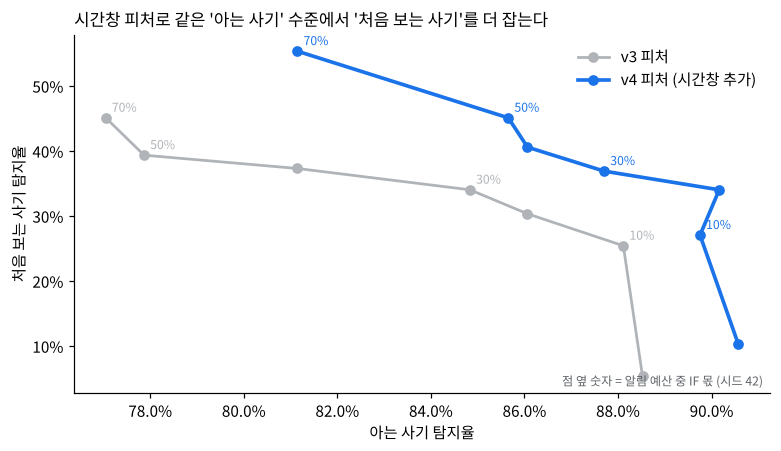

아는_사기       처음_보는_사기       처음보는_대면편취      
피처       v3    v4       v3    v4        v3    v4
IF_비중                                           
0.0    0.89  0.91     0.05  0.10      0.03  0.00
0.1    0.88  0.90     0.25  0.27      0.03  0.00
0.2    0.86  0.90     0.30  0.34      0.00  0.02
0.3    0.85  0.88     0.34  0.37      0.00  0.02
0.4    0.81  0.86     0.37  0.41      0.00  0.03
0.5    0.78  0.86     0.39  0.45      0.00  0.05
0.7    0.77  0.81     0.45  0.55      0.00  0.22

In [3]:
S3 = pd.read_csv(f"{RES}/window_share_seed42.csv")
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for tag, col, lab in [("v3", GREY, "v3 피처"), ("v4", BLUE, "v4 피처 (시간창 추가)")]:
    d = S3[S3.피처 == tag]
    ax.plot(d.아는_사기, d.처음_보는_사기, marker="o", color=col, lw=2.4 if tag == "v4" else 1.8, label=lab)
    for _, r in d.iterrows():
        if r.IF_비중 in (0.1, 0.3, 0.5, 0.7):
            ax.annotate(f"{r.IF_비중:.0%}", (r.아는_사기, r.처음_보는_사기), xytext=(4, 4), textcoords="offset points", fontsize=8, color=col)
ax.set_xlabel("아는 사기 탐지율"); ax.set_ylabel("처음 보는 사기 탐지율")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.set_title("시간창 피처로 같은 '아는 사기' 수준에서 '처음 보는 사기'를 더 잡는다", loc="left", fontsize=11)
ax.text(0.99, 0.02, "점 옆 숫자 = 알림 예산 중 IF 몫 (시드 42)", transform=ax.transAxes, ha="right", fontsize=8, color=DARK)
ax.legend(frameon=False, loc="upper right"); clean(ax); plt.tight_layout(); plt.show()
S3.pivot(index="IF_비중", columns="피처", values=["아는_사기", "처음_보는_사기", "처음보는_대면편취"]).round(2)

곡선이 오른쪽 위로 갈수록 좋다. v4 곡선이 v3보다 전체적으로 바깥에 있다. 예를 들어 아는 사기를 86% 수준으로 지키려면 v3는 IF 몫을 20%까지만 줄 수 있지만(처음 보는 사기 30%), v4는 40%까지 줄 수 있다(41%).

**그래도 대면편취는 어렵다.** IF 몫이 30%일 때 처음 보는 대면편취는 2%다. IF 혼자 예산을 다 쓰면 46%를 잡는데, 예산을 나누면 사칭·대출사기처럼 더 '튀는' 사기가 IF 몫을 먼저 차지한다. IF 몫을 70%까지 올려야 22%가 된다. 결론: 대면편취는 비지도로 버티는 유형이 아니라, 신고 라벨을 빨리 확보해 지도학습으로 잡아야 하는 유형이다. v2의 판단이 피처를 보강한 뒤에도 유지된다.

## 2. 운영 중 드리프트: 1년 반 시뮬레이션

실제 서비스에서 모델은 한 번 만들고 끝나지 않는다. 사기 수법이 바뀌고 고객 행동도 바뀐다. 이를 흉내 내려고 데이터를 2025-01 ~ 2026-06(18개월)로 늘리고, **2026-01부터** 세 가지 변화를 넣었다(`src/gen_data_v4.py`).

| 변화 | 내용 | 기존 사기와의 관계 |
| --- | --- | --- |
| 정상 행동 변화 (간편송금 확산) | 처음 보는 계좌로 송금(중고거래·더치페이)이 월 평균 4건 생김 | 사칭 사기의 핵심 신호(새 계좌)가 흔해짐 |
| 신종 1: 투자 리딩방 사기 | 새 계좌로 소액 송금 후 3~5일마다 금액을 1.3~1.7배씩 키워 5~9회 | 착취(반복 송금)와 모양이 비슷함 |
| 신종 2: 메신저피싱 상품권 결제 | 몇 시간 안에 처음 보는 가맹점에서 카드로 30~80만 원을 3~6회 | 기존 사기 4종은 카드를 쓰지 않음 → 완전히 새로운 형태 |

**운영 가정**

- 평가: 2025-10 ~ 2026-06, 월 단위. 4,000가구, 알림 예산은 가구당 월 0.1건(월 400건), 스태킹 70% + IF 30%.
- **라벨 지연 30일**: 가족 확인·신고가 들어오는 데 한 달이 걸린다고 본다. 시점 T에 학습할 때 T−30일 이전 거래의 라벨만 쓴다.
- IF는 라벨이 필요 없어 T 직전 90일 거래로 다시 학습한다.
- 알림 컷은 재학습 시점 직전 30일을 새 모델로 채점해 예산에 맞추고, **다음 재학습까지 고정**한다. 그래서 행동이 바뀌면 알림 수가 예산을 넘는다. 실제 운영과 같은 방식이다.
- 재학습 정책 세 가지: **고정**(2025-10에 한 번), **분기**(10·1·4월), **매월**.

실험 코드는 `src/exp_drift.py`. 시드 3개(42, 1, 2)로 돌렸다.

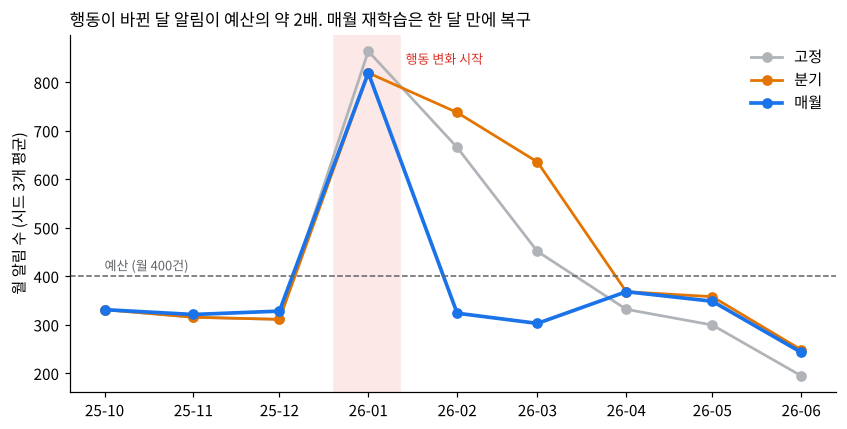

월,2025-10-01,2025-11-01,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01
정책,,,,,,,,,
고정,331,315,311,864,665,451,332,299,195
매월,331,321,328,819,324,303,368,348,243
분기,331,315,311,819,737,635,368,358,248


In [4]:
ALR = pd.read_csv(f"{RES}/drift_alerts.csv", parse_dates=["월"])
REC = pd.read_csv(f"{RES}/drift_recall.csv", parse_dates=["월"])
PSI = pd.read_csv(f"{RES}/drift_psi.csv", parse_dates=["월"])
POL = {"고정": GREY, "분기": ORANGE, "매월": BLUE}

a = ALR.groupby(["정책", "월"]).알림수.mean().unstack(0)
fig, ax = plt.subplots(figsize=(7.8, 4))
for p, c in POL.items():
    ax.plot(a.index, a[p], marker="o", color=c, lw=2.4 if p == "매월" else 1.8, label=p)
ax.axhline(400, color=DARK, ls="--", lw=1); ax.text(a.index[0], 412, "예산 (월 400건)", fontsize=8.5, color=DARK)
ax.axvspan(pd.Timestamp("2025-12-20"), pd.Timestamp("2026-01-12"), color="#fce8e6", zorder=0)
ax.text(pd.Timestamp("2026-01-14"), a.max().max() * 0.97, "행동 변화 시작", fontsize=8.5, color=RED)
ax.set_ylabel("월 알림 수 (시드 3개 평균)"); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%y-%m"))
ax.set_title("행동이 바뀐 달 알림이 예산의 약 2배. 매월 재학습은 한 달 만에 복구", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right"); clean(ax); plt.tight_layout(); plt.show()
a.round(0).astype(int).T

**읽는 법.** 2026-01에 간편송금이 늘면서 '처음 보는 계좌로 송금'이 갑자기 흔해졌다. 예전 기준으로 보면 이상한 거래가 폭증한 것이다. 세 정책 모두 1월에 알림이 예산을 크게 넘는다.

- **매월**: 2월 재학습 때 1월 데이터로 IF와 알림 컷을 다시 잡아 바로 예산 수준으로 돌아온다.
- **분기**: 다음 재학습(4월)까지 3개월 동안 과다 알림이 이어진다. 가족 입장에서는 헛알림이 몇 달 동안 쏟아지는 셈이다.
- **고정**: 3개월에 걸쳐 서서히 줄어든다. 하지만 기준이 낡은 채로 남아 신종 수법은 끝까지 못 잡는다(3절).

알림이 늘었다는 건 헛알림이 늘었다는 뜻이다. 헛알림이 쌓이면 사용자가 알림을 무시하게 되고, 진짜 사기 알림도 묻힌다.

### 무너지는 걸 어떻게 알아채나: PSI

PSI(Population Stability Index)는 '지금 데이터 분포가 학습할 때 분포와 얼마나 달라졌나'를 숫자 하나로 나타낸다.

$$\text{PSI} = \sum_{i} (q_i - p_i)\,\ln\frac{q_i}{p_i}$$

- $p_i$: 기준 기간(2025-04~08)에서 i번째 구간 비율, $q_i$: 이번 달 비율
- 구간은 기준 기간의 분위수로 나눈다. 0이 많은 피처는 '0' 구간을 따로 둔다.
- 업계 관행: 0.1 미만 안정, 0.1~0.25 주의, 0.25 이상 경고

라벨이 필요 없어서 **라벨 지연 30일을 기다리지 않고 당일에 알 수 있다**는 게 핵심이다.

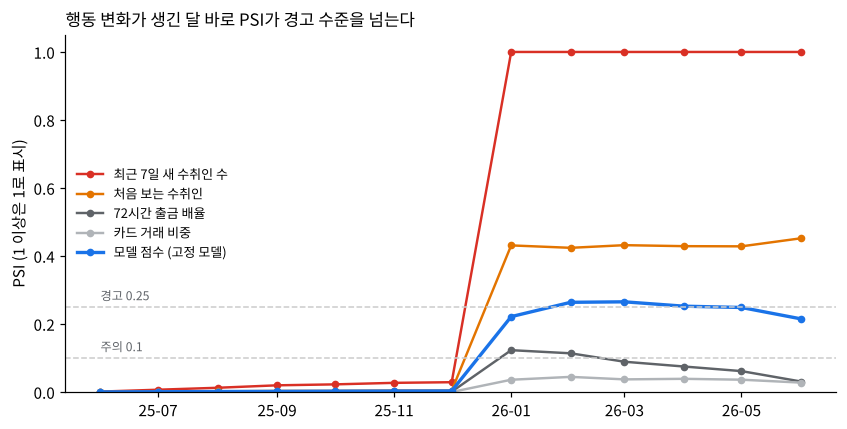

,최근 7일 새 수취인 수,처음 보는 수취인,72시간 출금 배율,카드 거래 비중,모델 점수 (고정 모델)
월,,,,,
25-06,0.001,0.000,0.000,0.000,0.000
25-07,0.007,0.001,0.000,0.000,0.001
25-08,0.013,0.002,0.001,0.000,0.001
25-09,0.020,0.003,0.000,0.000,0.002
25-10,0.022,0.003,0.001,0.000,0.003
25-11,0.027,0.004,0.001,0.000,0.003
25-12,0.029,0.004,0.001,0.000,0.003
26-01,2.077,0.431,0.123,0.036,0.222
26-02,2.352,0.424,0.114,0.045,0.264


In [5]:
p = PSI.groupby("월").mean(numeric_only=True)
show = {"newpayee_n_7d": "최근 7일 새 수취인 수", "new_payee": "처음 보는 수취인", "out_72h_ratio": "72시간 출금 배율",
        "t_card": "카드 거래 비중", "점수(고정 모델)": "모델 점수 (고정 모델)"}
fig, ax = plt.subplots(figsize=(7.8, 4))
cols = [RED, ORANGE, DARK, GREY, BLUE]
for (f, lab), c in zip(show.items(), cols):
    ax.plot(p.index, p[f].clip(upper=1.0), marker="o", ms=4, color=c, lw=2.2 if "점수" in lab else 1.6, label=lab)
for y, lab in [(0.1, "주의 0.1"), (0.25, "경고 0.25")]:
    ax.axhline(y, color="#ccc", ls="--", lw=1); ax.text(p.index[0], y + 0.02, lab, fontsize=8, color=DARK)
ax.set_ylim(0, 1.05); ax.set_ylabel("PSI (1 이상은 1로 표시)"); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%y-%m"))
ax.set_title("행동 변화가 생긴 달 바로 PSI가 경고 수준을 넘는다", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, loc="center left"); clean(ax); plt.tight_layout(); plt.show()
p[list(show)].rename(columns=show).round(3).set_index(p.index.strftime("%y-%m"))

- 2025년에는 모든 피처가 0.03 아래로 안정적이다.
- 2026-01에 '최근 7일 새 수취인 수'가 2 이상, '처음 보는 수취인'이 약 0.43으로 경고 기준을 크게 넘는다. 모델 점수 분포의 PSI도 0.22~0.27로 주의와 경고의 경계까지 올라간다.
- **카드 거래 비중은 거의 안 움직인다.** 신종 상품권 사기는 전체 거래에서 너무 적어 분포 지표로는 보이지 않는다. PSI는 '고객 전체가 바뀌는 것'은 잘 잡지만, '소수의 새 사기'는 못 잡는다. 이건 다음 절의 결과와 이어진다.

## 3. 재학습 주기별 탐지율

In [6]:
def wavg(d): return np.average(d.탐지율, weights=d.에피소드)
summ = REC.groupby(["정책", "구분"]).apply(wavg).unstack(0)[["고정", "분기", "매월"]]
sd = REC.groupby(["seed", "정책", "구분"]).apply(wavg).groupby(["정책", "구분"]).std().unstack(0)[["고정", "분기", "매월"]]
pd.DataFrame({p: [f"{summ.loc[g, p]:.0%} ± {sd.loc[g, p]:.0%}" for g in summ.index] for p in summ.columns}, index=summ.index)

,고정,분기,매월
구분,,,
기존 수법,74% ± 5%,81% ± 2%,82% ± 3%
신종: 상품권 결제,0% ± 0%,53% ± 5%,64% ± 5%
신종: 투자사기,91% ± 5%,97% ± 4%,95% ± 3%


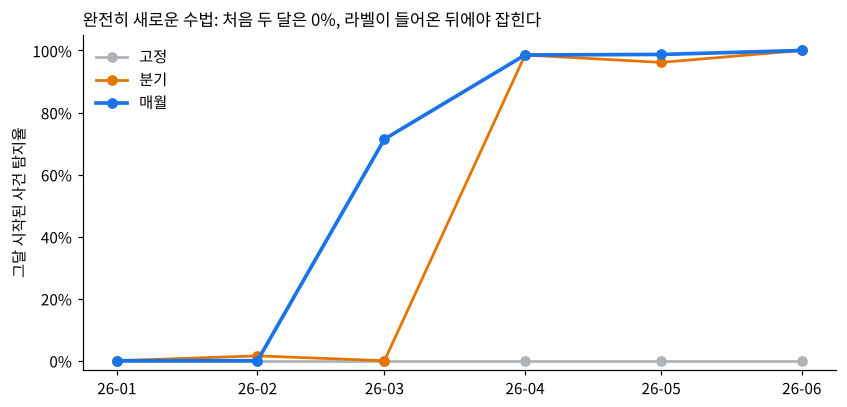

월,26-01,26-02,26-03,26-04,26-05,26-06
정책,,,,,,
고정,0.0,0.00,0.00,0.00,0.00,0.0
매월,0.0,0.00,0.71,0.99,0.99,1.0
분기,0.0,0.02,0.00,0.99,0.96,1.0


In [7]:
g = REC[REC.구분 == "신종: 상품권 결제"].groupby(["정책", "월"]).apply(wavg).unstack(0)
fig, ax = plt.subplots(figsize=(7.8, 3.8))
for p, c in POL.items():
    ax.plot(g.index, g[p], marker="o", color=c, lw=2.4 if p == "매월" else 1.8, label=p)
ax.set_ylim(-0.03, 1.05); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter("%y-%m"))
ax.set_ylabel("그달 시작된 사건 탐지율")
ax.set_title("완전히 새로운 수법: 처음 두 달은 0%, 라벨이 들어온 뒤에야 잡힌다", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left"); clean(ax); plt.tight_layout(); plt.show()
g.round(2).set_index(g.index.strftime("%y-%m")).T

**세 가지가 보인다.**

1. **기존 수법**: 고정 74%, 분기 81%, 매월 82%. 라벨이 쌓이고 컷이 최신으로 유지되면서 오른다. 고정 모델은 학습 사건이 60~90건뿐이라 출발점부터 낮다. 분기와 매월의 차이는 작다.
2. **신종 1 (투자 리딩방)**: 고정 모델도 91%를 잡는다. 반복 송금이라는 모양이 기존 '착취'와 비슷해서, 이름은 새 수법이지만 모델에게는 새 형태가 아니다.
3. **신종 2 (상품권 카드 결제)**: 모든 정책이 처음 2개월 동안 사실상 0%다. **비지도 IF도 거의 못 잡았다**(시드 3개 × 6개월 중 한 달에 4.5%가 전부). IF가 쓰는 피처에 '짧은 시간 카드 연속 결제'를 나타내는 게 없고, 같은 시기 간편송금 폭증으로 IF 몫의 알림이 그쪽에 쓰였다. 매월 재학습은 라벨이 들어온 3월부터 71%를 잡고 4월에는 거의 다 잡는다. 분기는 4월부터, 고정은 끝까지 0%다. 기간 전체로는 고정 0%, 분기 53%, 매월 64%.

**v2의 2트랙 결론을 고쳐야 할 부분.** 비지도 트랙은 '처음 보는 사기'의 안전망이지만, **피처가 보는 범위 안에서만** 안전망이다. 송금·인출 위주로 피처를 만들었기 때문에 카드 사기는 원천적으로 보이지 않았다. 새로운 경로(카드, 간편결제, 오픈뱅킹)가 생기면 그 경로를 묘사하는 피처부터 추가해야 한다.

## 4. 운영 규칙 제안

실험 결과를 운영 규칙으로 옮기면 다음과 같다.

| 규칙 | 근거 |
| --- | --- |
| 기본은 **매월 재학습** | 기존 수법 탐지율은 분기와 비슷하지만, 행동 변화 후 과다 알림이 1개월 안에 복구되고(분기는 3개월) 신종 탐지가 1개월 빨리 시작됨 |
| **PSI 0.25 이상이거나 알림 수가 예산의 1.5배를 넘으면 즉시 재학습**(월 중간이라도) | 라벨 없이 당일에 알 수 있는 신호. 2026-01에 둘 다 발동 |
| 신고가 들어온 신종 사례는 **라벨 지연 없이 바로 학습 데이터에 추가** | 상품권 사기는 라벨 도착 시점이 곧 탐지 시작 시점이었음 |
| 새 거래 경로가 생기면 **그 경로의 시간창 피처를 먼저 추가** | 피처가 없으면 비지도도 못 잡음 |
| 대면편취는 비지도에 기대지 말고 **신고 라벨 확보를 우선** | 시간창 피처로도 비지도 30% 몫에서는 2% |

## 5. 한계

- 드리프트 시나리오는 직접 설계한 것이다. 실제 변화는 더 느리거나, 여러 변화가 겹쳐 온다.
- 라벨 지연을 모든 사기에 똑같이 30일로 뒀다. 실제로는 놓친 사기는 아예 라벨이 안 들어오기도 한다(잡힌 것만 학습하는 편향).
- 월별 사건 수가 10~40건이라 월 단위 탐지율은 흔들림이 크다. 정책 간 비교는 기간 전체 평균으로 본다.